# 2. Optimality, comparisons and revision plans

How EVCC-A compares with the best tested order over the whole cohort, why the public Tolsa case cannot be reached by an order of the raw properties, how two multivariate proposal methods fare under the same gates, and what the revision plans contain.

In [1]:
import pandas as pd
from IPython.display import display

from evcca import best_ordered, certificate, exact_geometric_columns, solve_master
from evcca.candidates import interval_combinations
from evcca.study.cohort import article_policy, load_specimens
from evcca.study.comparators import graph_ward_columns, spectral_cop_columns, verify_comparison
from evcca.study.diagnostics import TOLSA
from evcca.study.notebook import record, show_figure, table
from evcca.study.paths import RESULTS
from evcca.study.verify import plans

## 2.1 Cohort results (Table 2)

Four properties, compact mode. A context is strictly feasible when it has at least one group and its referrals fit the review budget, max(1, ⌊0.1 n⌋); its assigned specimens are then counted as within-budget specimens.

In [2]:
metrics = table("metrics").query("profile == 'four' and mode == 'compact'")
metrics.groupby("method").agg(
    contexts=("context_id", "size"),
    specimens=("n", "sum"),
    strict=("strict_feasible", "sum"),
    within_budget=("strict_accepted_n", "sum"),
    optimal=("optimal", "sum"),
)

,contexts,specimens,strict,within_budget,optimal
method,,,,,
evcca,19,247,10,120,19
ordered,19,247,10,119,19


In [3]:
by_context = metrics.pivot(index="context_id", columns="method", values=["n", "A", "K", "strict_accepted_n"])
by_context.drop(columns=("n", "ordered")).droplevel(1, axis=1).set_axis(
    ["n", "A, EVCC-A", "A, order", "K, EVCC-A", "K, order", "within budget, EVCC-A", "within budget, order"], axis=1
)

,n,"A, EVCC-A","A, order","K, EVCC-A","K, order","within budget, EVCC-A","within budget, order"
context_id,,,,,,,
FI::Haapa-Kimola | CLAY | ILOT,24,18,18,1,1,0,0
FI::Haarajoki | CLAY | ILOT,21,5,5,1,1,0,0
FI::Söderkulla-Nikkilä | CLAY | ILOT,18,11,11,1,1,0,0
"FI::Tolsa, Kirkkonummi | CLAY | ILOT",24,0,1,2,3,24,23
FI::Östersundom | CLAY | ILOT,8,8,8,0,0,0,0
P07 | LOAM | g | sigma3=100.0,12,0,0,1,1,12,12
P09 | LOAM | m | sigma3=50.0,12,0,0,2,2,12,12
P15 | LOAM | l | sigma3=50.0,12,4,4,1,1,0,0
PRIMARY::P01 | CLAY | C,8,2,2,1,1,0,0


## 2.2 Tolsa

Tolsa has 24 specimens in three boreholes. The cell below enumerates the complete family of admissible groups from the data and solves both methods again.

In [4]:
specimens = load_specimens()
tolsa = specimens[specimens.context_id.eq(TOLSA)].sort_values("sample_id").reset_index(drop=True)
policy = article_policy("FI-CLAY")
columns = exact_geometric_columns(tolsa, policy)
ordered, _ = best_ordered(tolsa, policy, columns)
joint = solve_master(tolsa, policy, columns, witness=ordered)
pd.Series(
    {
        "interval combinations, N_geom": interval_combinations(tolsa),
        "admissible groups": len(columns),
        "best order (A, K)": ordered.objective[:2],
        "EVCC-A (A, K)": tuple(int(v) for v in joint.objective[:2]),
        "EVCC-A proven optimal": joint.optimal,
    }
)

interval combinations, N_geom     21296
admissible groups                  2001
best order (A, K)                (1, 3)
EVCC-A (A, K)                    (0, 2)
EVCC-A proven optimal              True
dtype: object

Only one partition keeps all 24 specimens in two groups. In the raw properties the convex hulls of its two groups intersect, with strictly positive weight on every specimen and affine rank four. Then no nonconstant linear combination of the properties can order the specimens so that the groups become two runs. After a log transform the hulls separate, and an order along the separating direction finds the partition.

In [5]:
table("tolsa_projection_checks")[
    ["transform", "hulls_intersect", "positive_all_weights", "minimum_weight", "affine_rank",
     "separator_order_A", "separator_order_K"]
]

,transform,hulls_intersect,positive_all_weights,minimum_weight,affine_rank,separator_order_A,separator_order_K
0,raw,True,True,0.000856,4,NaN,NaN
1,log,False,False,0.000000,4,0.0,2.0


The JSON file stores the raw-space weights as exact fractions. The check is done in rational arithmetic (`python -m evcca.certificate results/tolsa_hull_witnesses.json`):

In [6]:
witnesses = record("tolsa_hull_witnesses")
raw = next(w for w in witnesses["witnesses"] if w["transform"] == "raw")
certificate.verify(raw["exact_decimal_certificate"])

True

Which gates make the difference: with all gates the order falls one specimen and one group behind. Without the extremum gate, without the contiguity rule, or without the density property the advantage disappears. Thirty-two random directions do not help the order.

In [7]:
ablations = table("tolsa_ablations")
ablations.pivot(index="variant", columns="method", values=["A", "K"]).loc[ablations.variant.unique()]

A             K        
method                 evcca ordered evcca ordered
variant                                           
all_gates                  0       1     2       3
no_extremum_gate           0       0     2       2
no_borehole_contiguity     0       0     2       2
drop_alpha                 0       1     2       3
drop_rho                   0       0     2       2
drop_water_pct             0       1     2       2
drop_su                    0       1     2       3
32_random_directions       0       1     2       3

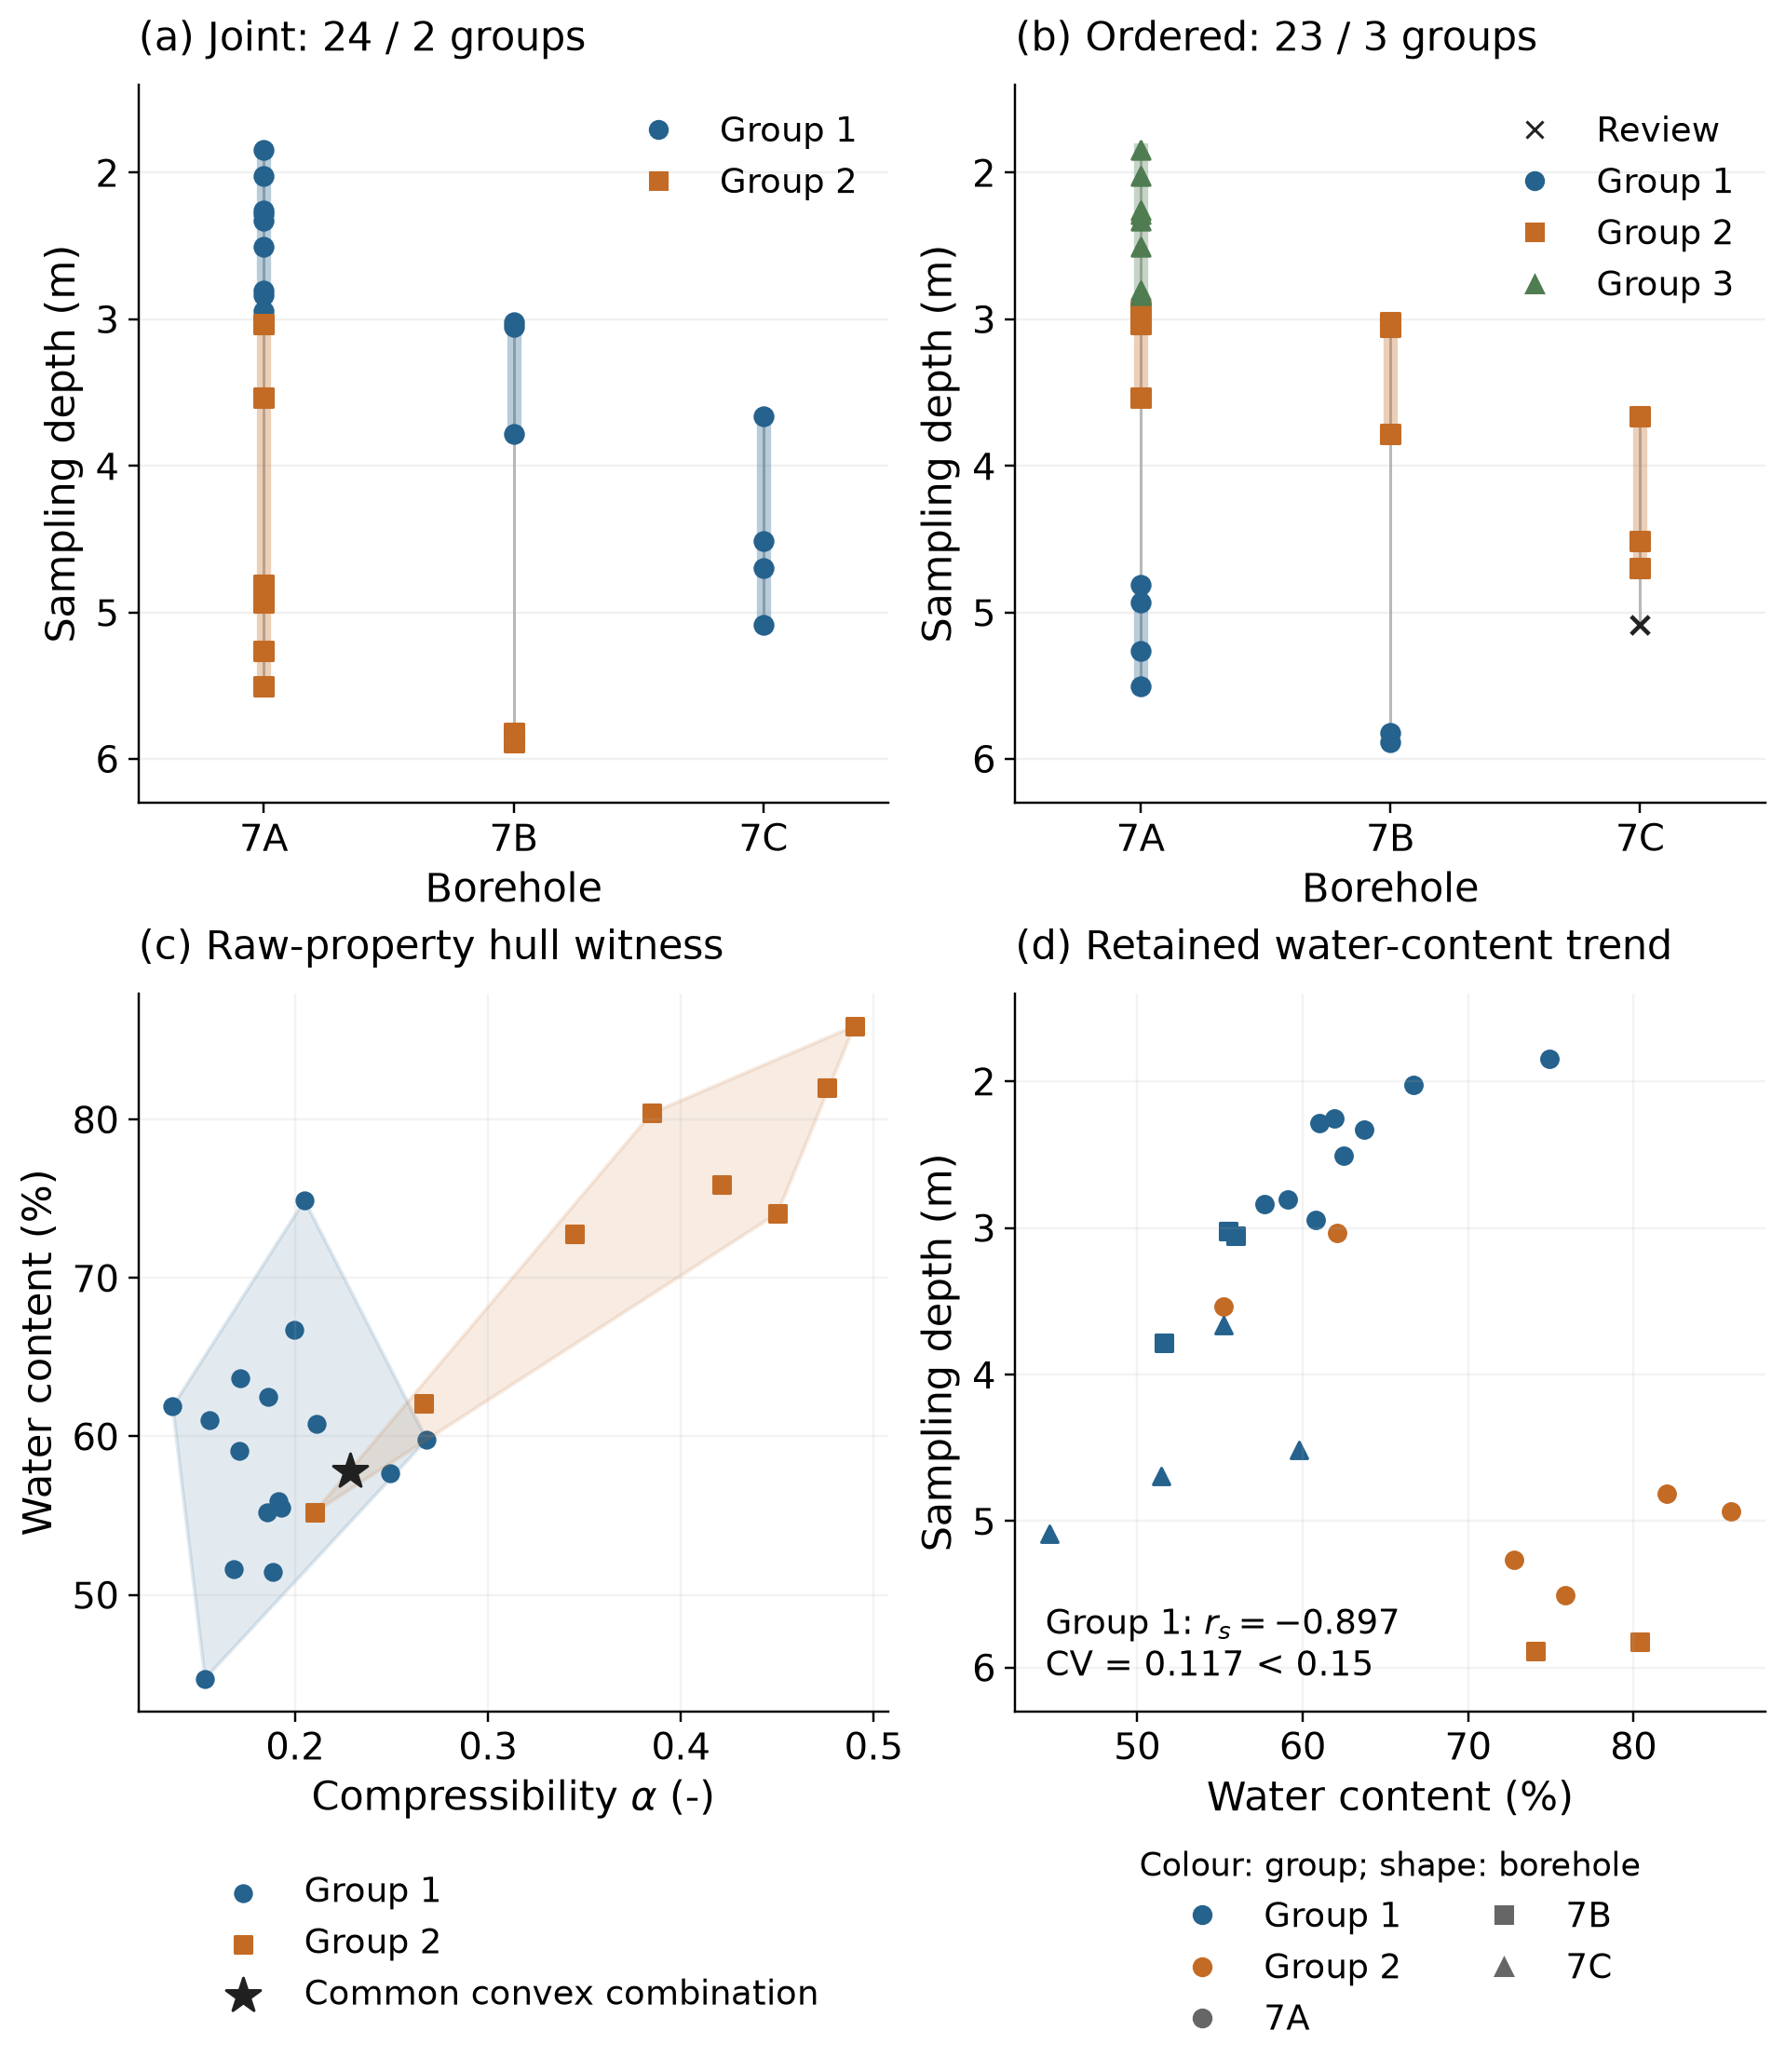

In [8]:
show_figure("fig1_tolsa_geometry")

## 2.3 Graph Ward and Spectral + COP (Fig. 4)

Two multivariate proposal methods use the same gates and the same lexicographic master as EVCC-A, but choose groups only from the candidates they generate.

- **Graph Ward** keeps every node of agglomerative Ward forests. The forests are built on feature-neighbour graphs (3, 5, 8 or all neighbours; standardized raw and log properties) with links between consecutive specimens of a borehole; a merger must stay one interval per borehole and must not cross a material barrier.
- **Spectral + COP** embeds the specimens with the leading eigenvectors of a normalized affinity, then assigns them borehole by borehole to the nearest permitted centre (COP-style cannot-links, one interval per borehole, review when no centre is permitted), for K = 1, …, ⌊n/6⌋ and 20 seeded runs.

Both pools also receive the whole context, each source unit and each pair of source units, and are extended by greedy trimming of interval endpoints. The source-units-only control shows what these common candidates give on their own. The protocol is in `docs/comparators.md`; `python -m evcca.study.comparators --output <new folder>` recomputes `results/comparators/`.

In [9]:
pd.Series(verify_comparison())

status                      verified
outcomes                        1980
selected_groups_audited         2128
admissibility_violations           0
contexts                          19
specimens                        247
dtype: object

Every selected group passes the gates. The counts are group appearances over methods, seeds, policies and modes, not independent geological units.

In [10]:
table("comparators/group_audit").groupby("method").agg(
    group_appearances=("group", "size"),
    violations=("compliant", lambda ok: int((~ok).sum())),
    largest_CV_ratio=("max_cv_ratio", "max"),
    largest_extremum_ratio=("max_nu_ratio", "max"),
).round(4)

,group_appearances,violations,largest_CV_ratio,largest_extremum_ratio
method,,,,
graph_ward,97,0,0.9952,0.9993
source_union,87,0,0.9952,0.9967
spectral_cop,1944,0,0.9952,0.9997


Assigned / within-budget specimens in compact mode (Supplementary Table S6). Within-budget specimens count only in contexts whose referrals fit the review budget; assigned specimens also include partial covers. For Spectral + COP the range over the 20 runs is shown where it varies.

In [11]:
summary = table("comparators/summary").query("mode == 'compact'")
methods = {
    "evcca": "EVCC-A",
    "ordered": "Best tested order",
    "graph_ward": "Graph Ward",
    "spectral_cop": "Spectral + COP",
    "source_union": "Source units only",
}
policies = {"nominal": "Nominal", "nu_5pct": "Extremum 5 %", "cv_10pct_nu_5pct": "CV 10 % + extremum 5 %"}


def span(low, high):
    return f"{low:.0f}" if low == high else f"{low:.0f}–{high:.0f}"


summary = summary.assign(
    entry=[
        f"{span(r.assigned_min, r.assigned_max)} / {span(r.accepted_min, r.accepted_max)}"
        for r in summary.itertuples()
    ]
)
summary.pivot(index="method", columns="policy", values="entry").loc[list(methods), list(policies)].rename(
    index=methods, columns=policies
)

policy,Nominal,Extremum 5 %,CV 10 % + extremum 5 %
method,,,
EVCC-A,186 / 120,184 / 120,170 / 120
Best tested order,185 / 119,178 / 105,162 / 94
Graph Ward,178 / 118,172 / 105,162 / 94
Spectral + COP,179–185 / 119,177 / 105,162 / 94
Source units only,165 / 95,143 / 83,133 / 72


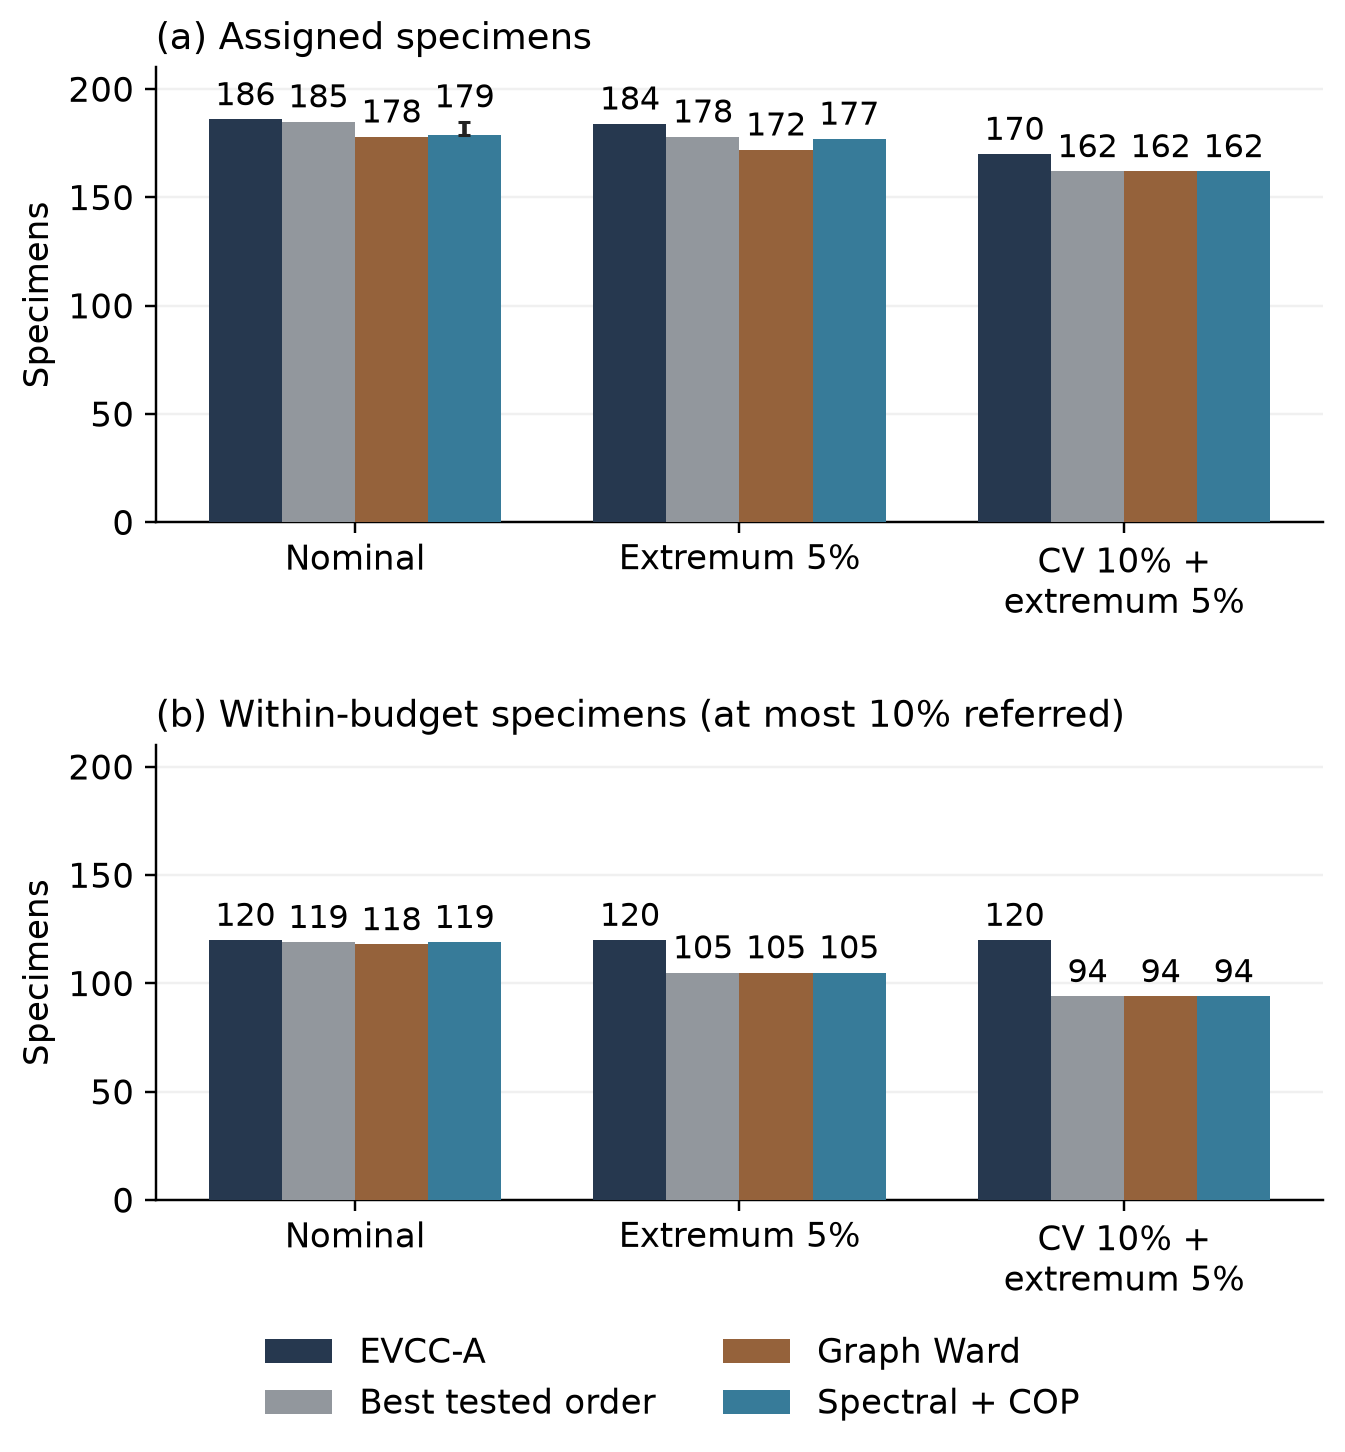

In [12]:
show_figure("fig4_graph_spectral")

Contexts (of 19) whose result matches the complete optimum: `leading` compares (A, K), `full` also compares B within 1e-9.

In [13]:
matches = table("comparators/summary").query("mode == 'compact'").set_index(["method", "policy"])
matches = matches[["leading_min", "leading_max", "full_min", "full_max"]].astype(int)
matches.unstack("policy").reorder_levels([1, 0], axis=1)[list(policies)].loc[list(methods)]

policy           nominal                                   nu_5pct                               cv_10pct_nu_5pct                              
             leading_min leading_max full_min full_max leading_min leading_max full_min full_max      leading_min leading_max full_min full_max
method                                                                                                                                         
evcca                 19          19       19       19          19          19       19       19               19          19       19       19
ordered               18          18       16       16          16          16       15       15               16          16       15       15
graph_ward            16          16       14       14          15          15       14       14               16          16       14       14
spectral_cop          16          17       14       14          15          15       14       14               16          16       14       14
source_union          15          15       13       13          14          14       13       13               15          15       13       13

At nominal Tolsa every spectral run keeps all 24 specimens but needs three groups; Graph Ward and the best order refer one specimen. The certified two-group partition is in none of the generated pools. The cell rebuilds both pools from the measurements (one spectral seed) and solves them again.

In [14]:
live = []
for name, generate in [("Graph Ward", graph_ward_columns), ("Spectral + COP", spectral_cop_columns)]:
    pool = generate(tolsa, policy)
    result = solve_master(tolsa, policy, pool, scope="proposal_pool")
    live.append(
        dict(method=name, admissible_candidates=len(pool), A=int(result.objective[0]), K=int(result.objective[1]))
    )
live.append(
    dict(method="EVCC-A", admissible_candidates=len(columns), A=int(joint.objective[0]), K=int(joint.objective[1]))
)
pd.DataFrame(live)

,method,admissible_candidates,A,K
0,Graph Ward,23,1,3
1,Spectral + COP,75,0,3
2,EVCC-A,2001,0,2


Haapa-Kimola shows why a proposal search that finds no group is not a proof that none exists. The complete family contains admissible groups and EVCC-A assigns six specimens, but Graph Ward and most spectral runs generate none, so their master refers all 24.

In [15]:
compared = table("comparators/compared_results")
haapa = compared[
    compared.context_id.str.startswith("FI::Haapa") & compared.policy.eq("nominal") & compared["mode"].eq("compact")
]
haapa.groupby("method").agg(runs=("run", "size"), runs_without_a_group=("K", lambda k: int((k == 0).sum())))

,runs,runs_without_a_group
method,,
evcca,1,0
graph_ward,1,1
ordered,1,0
source_union,1,1
spectral_cop,20,16


Repair, 11 primary contexts. At nominal limits every pool, including the source-units-only control, reaches the complete repair optimum; in P13 loam C they all recover the upper/lower separation, (A, D, K) = (0, 39, 2). Under either reserve they miss two optima. In P06 clay C complete search still keeps all 12 specimens in two groups, while the pools refer three, more than the review budget allows; this accounts for the 72 versus 60 within-budget specimens.

In [16]:
repair = compared[compared["mode"].eq("repair") & compared.policy.ne("nominal")]
missed = repair.loc[~repair.leading_match, ["policy", "context_id"]].drop_duplicates()
repair.merge(missed).groupby(["policy", "context_id", "method"]).agg(
    runs=("run", "size"), A=("A", "max"), D=("D", "max"), K=("K", "max"), within_budget=("strict_accepted_n", "max")
)

runs  A   D  K  within_budget
policy           context_id              method                                     
cv_10pct_nu_5pct PRIMARY::P06 | CLAY | C evcca            1  0  20  2             12
                                         graph_ward       1  3  34  1              0
                                         ordered          1  3  34  1              0
                                         source_union     1  3  34  1              0
                                         spectral_cop    20  3  34  1              0
                 PRIMARY::P13 | CLAY | C evcca            1  0  20  2             12
                                         graph_ward       1  0  36  1             12
                                         ordered          1  0  32  2             12
                                         source_union     1  0  36  1             12
                                         spectral_cop    20  0  36  1             12
nu_5pct          PRIMARY::P06 | CLAY | C evcca            1  0  20  2             12
                                         graph_ward       1  3  34  1              0
                                         ordered          1  3  34  1              0
                                         source_union     1  3  34  1              0
                                         spectral_cop    20  3  34  1              0
                 PRIMARY::P13 | CLAY | C evcca            1  0  20  2             12
                                         graph_ward       1  0  36  1             12
                                         ordered          1  0  32  2             12
                                         source_union     1  0  36  1             12
                                         spectral_cop    20  0  36  1             12

In [17]:
table("comparators/summary").query("mode == 'repair'").pivot(
    index="method", columns="policy", values="accepted_median"
).loc[list(methods), list(policies)].astype(int).rename(index=methods, columns=policies)

policy,Nominal,Extremum 5 %,CV 10 % + extremum 5 %
method,,,
EVCC-A,72,72,72
Best tested order,72,60,60
Graph Ward,72,60,60
Spectral + COP,72,60,60
Source units only,72,60,60


**Other review budgets (Table 4).** The budget only decides which results count, so the comparison can be recounted without solving again. `none` counts contexts in which every specimen is grouped; `unlimited` counts all assigned specimens. Every pool is a subset of the complete family under the same objective, so EVCC-A never has fewer; the budget changes the size of the gap.

In [18]:
budgets = table("robustness/review_budgets")
order = ["none", "one", "10pct", "20pct", "25pct", "unlimited"]
cells = budgets.assign(
    entry=[span(r.within_budget_min, r.within_budget_max) for r in budgets.itertuples()]
)
for point in ["nu_5pct", "cv_10pct_nu_5pct", "nominal"]:
    print(policies[point])
    display(
        cells[cells.policy.eq(point)]
        .pivot(index="budget", columns="method", values="entry")
        .loc[order, list(methods)]
        .rename(columns=methods)
    )

Extremum 5 %


method,EVCC-A,Best tested order,Graph Ward,Spectral + COP,Source units only
budget,,,,,
none,89,41,41,41,41
one,120,83,83,83,83
10pct,120,105,105,105,83
20pct,129,114,114,114,92
25pct,151,145,145,145,123
unlimited,184,178,172,177,143


CV 10 % + extremum 5 %


method,EVCC-A,Best tested order,Graph Ward,Spectral + COP,Source units only
budget,,,,,
none,89,41,41,41,41
one,120,72,72,72,72
10pct,120,94,94,94,72
20pct,120,94,94,94,72
25pct,142,134,134,134,112
unlimited,170,162,162,162,133


Nominal


method,EVCC-A,Best tested order,Graph Ward,Spectral + COP,Source units only
budget,,,,,
none,89,65,53,77,53
one,120,119,118,119,95
10pct,120,119,118,119,95
20pct,129,128,127,128,104
25pct,151,150,149,150,126
unlimited,186,185,178,179–185,165


**A wider proposal search.** `joined` merges the Graph Ward pool with the pools of all 20 spectral runs. The `_wide` pools use 2, 3, 4, 5, 6, 8, 10, 12 or all neighbours (Graph Ward; up to 10 for Spectral + COP), bandwidth factors 0.25, 0.5, 1, 1.5, 2 and 4, up to 100 assignment iterations and 100 seeds. The wide spectral search reaches the two-group optimum at nominal Tolsa, but no pool finds any two-group full cover of P09 loam, or of P06 clay C under the reserves.

In [19]:
wide = table("robustness/wide_search").query("mode == 'compact'")
wide.groupby(["method", "policy"]).agg(
    assigned=("assigned_n", "sum"), within_budget=("strict_accepted_n", "sum"), largest_pool=("feasible_columns", "max")
).unstack("policy")

assigned                    within_budget                     largest_pool                
policy            cv_10pct_nu_5pct nominal nu_5pct cv_10pct_nu_5pct nominal nu_5pct cv_10pct_nu_5pct nominal nu_5pct
method                                                                                                              
graph_ward_wide                162     178     172               94     118     105               28      31      28
joined                         162     185     178               94     119     105              109     135     109
joined_wide                    163     185     180               95     119     107              222     301     240
spectral_cop_wide              163     185     180               95     119     107              222     301     240

In [20]:
wide[wide.context_id.str.contains("Tolsa|P06|P09")].pivot(
    index=["context_id", "policy"], columns="method", values=["A", "K"]
)

A                                                    K                     \
method                                                graph_ward_wide joined joined_wide spectral_cop_wide graph_ward_wide joined joined_wide   
context_id                           policy                                                                                                     
FI::Tolsa, Kirkkonummi | CLAY | ILOT cv_10pct_nu_5pct               2      2           1                 1               3      3           3   
                                     nominal                        1      0           0                 0               3      3           2   
                                     nu_5pct                        2      2           0                 0               3      2           4   
P09 | LOAM | m | sigma3=50.0         cv_10pct_nu_5pct               3      3           3                 3               1      1           1   
                                     nominal                        1      1           1                 1               1      1           1   
                                     nu_5pct                        1      1           1                 1               1      1           1   
PRIMARY::P06 | CLAY | C              cv_10pct_nu_5pct               3      3           3                 3               1      1           1   
                                     nominal                        0      0           0                 0               2      2           2   
                                     nu_5pct                        3      3           3                 3               1      1           1   

                                                                         
method                                                spectral_cop_wide  
context_id                           policy                              
FI::Tolsa, Kirkkonummi | CLAY | ILOT cv_10pct_nu_5pct                 3  
                                     nominal                          2  
                                     nu_5pct                          4  
P09 | LOAM | m | sigma3=50.0         cv_10pct_nu_5pct                 1  
                                     nominal                          1  
                                     nu_5pct                          1  
PRIMARY::P06 | CLAY | C              cv_10pct_nu_5pct                 1  
                                     nominal                          2  
                                     nu_5pct                          1

## 2.4 Revision plans (Table 5)

Primary contexts, four properties, nominal policy. `L` is the number of plans tied with the optimum on every criterion before the dispersion tie-breaker; the tie-breaker then selects one plan in every case.

In [21]:
summary = table("revision_plan_summary").query("profile == 'four' and cv_reserve == 0 and nu_reserve == 0")
operations = {
    "preserve_assigned_operations": "preserve",
    "merge_operations": "merge",
    "rebuild_operations": "rebuild",
    "review_operations": "review",
}
summary.set_index(["context_id", "mode"])[["A", "K", "D", "leading_optimal_plans", *operations]].rename(
    columns={"leading_optimal_plans": "L", **operations}
)

A  K   D     L  preserve  merge  rebuild  review
context_id               mode                                                     
PRIMARY::P01 | CLAY | C  compact  2  1   8     1         0      1        0       1
                         repair   2  1   8     1         0      1        0       1
PRIMARY::P01 | CLAY | J  compact  2  1  20     1         0      1        0       1
                         repair   2  1  20     1         0      1        0       1
PRIMARY::P01 | LOAM | pr compact  4  1  15     1         0      1        0       1
                         repair   4  1  15     1         0      1        0       1
PRIMARY::P06 | CLAY | C  compact  0  2  20    84         0      0        1       0
                         repair   0  2   0     1         2      0        0       0
PRIMARY::P08 | CLAY | C  compact  3  1  27     6         0      1        0       1
                         repair   3  1  27     3         0      1        0       1
PRIMARY::P08 | CLAY | J  compact  1  1  15     1         0      1        0       1
                         repair   1  1  15     1         0      1        0       1
PRIMARY::P08 | LOAM | C  compact  1  1   7     1         0      1        0       1
                         repair   1  1   7     1         0      1        0       1
PRIMARY::P13 | CLAY | C  compact  0  1  36     1         0      1        0       0
                         repair   0  2   0     1         2      0        0       0
PRIMARY::P13 | LOAM | C  compact  0  2  59  1331         0      0        1       0
                         repair   0  2  39     1         0      2        0       0
PRIMARY::P13 | LOAM | f  compact  1  1  15     1         0      1        0       1
                         repair   1  1  15     1         0      1        0       1
PRIMARY::P13 | LOAM | g  compact  1  1  22     2         0      1        0       1
                         repair   1  1  22     1         0      1        0       1

`plans` reads every plan in `revision_plans.json` (both profiles, nominal and 5 % extremum reserve), checks that each alternative covers its context, has the stated A, K and D, and that the Rand index of each selected plan equals 1 − D / C(n, 2). It returns the operations found; no plan contains a pure split or a partial transfer.

In [22]:
plans(RESULTS)

{'plan_sets': 88,
 'alternatives': 2634,
 'selected_operations': {'merge': 64,
  'review': 64,
  'rebuild': 14,
  'preserve_assigned': 8},
 'all_operations': {'merge': 104,
  'review': 100,
  'rebuild': 2520,
  'preserve_assigned': 12}}

Why specimens were referred. `ASSIGNMENT_COMPETITION`: the specimen fits an admissible group that lost in the global cover. `SINGLE_GATE_DEFICIT`: relaxing one gate would admit a group containing it (one row per such gate). `JOINT_GATE_DEFICIT`: no single relaxation is enough.

In [23]:
reasons = table("review_reasons").query("profile == 'four'")
reasons[["context_id", "sample_id", "reason_code", "gate", "witness_n", "additional_complete_records_lower_bound"]]

,context_id,sample_id,reason_code,gate,witness_n,additional_complete_records_lower_bound
0,PRIMARY::P01 | CLAY | C,P01-S0047,SINGLE_GATE_DEFICIT,minimum_size,5,1
1,PRIMARY::P01 | CLAY | C,P01-S0047,SINGLE_GATE_DEFICIT,material_barrier,6,0
2,PRIMARY::P01 | CLAY | C,P01-S0068,JOINT_GATE_DEFICIT,minimum_size;cv:e0,2,4
3,PRIMARY::P01 | CLAY | J,P01-S0069,ASSIGNMENT_COMPETITION,none,6,0
4,PRIMARY::P01 | CLAY | J,P01-S0091,SINGLE_GATE_DEFICIT,cv:e0,6,0
5,PRIMARY::P01 | LOAM | pr,P01-S0070,SINGLE_GATE_DEFICIT,minimum_size,5,1
6,PRIMARY::P01 | LOAM | pr,P01-S0070,SINGLE_GATE_DEFICIT,nu:cohesion,6,0
7,PRIMARY::P01 | LOAM | pr,P01-S0169,SINGLE_GATE_DEFICIT,minimum_size,3,3
8,PRIMARY::P01 | LOAM | pr,P01-S0183,SINGLE_GATE_DEFICIT,minimum_size,3,3
9,PRIMARY::P01 | LOAM | pr,P01-S0202,SINGLE_GATE_DEFICIT,minimum_size,3,3


## 2.5 Independent check

Two parts of the guarantee are checked separately. First, the family: for every context, at nominal limits and at the joint 10 % CV / 5 % extremum reserve, the groups found by enumerating borehole intervals are exactly those found by screening all 2^n subsets.

In [24]:
family = table("robustness/family_check")
family.groupby(["cv_reserve", "nu_reserve"]).agg(
    contexts=("context_id", "size"), subsets=("subsets", "sum"), identical=("identical", "all")
)

,,contexts,subsets,identical
cv_reserve,nu_reserve,,,
0.0,0.00,19,36072960,True
0.1,0.05,19,36072960,True


Second, the optimizer: for contexts with at most 18 specimens, an exact-cover search over the same family finds the same optimum as the MILP, in both modes. The MILP itself (HiGHS through `scipy.optimize.milp`) accepts a lexicographic stage only with an optimal status and a relative gap of at most 1e-8.

In [25]:
table("oracle_checks").groupby(["profile", "mode"]).matches.agg(["size", "sum"])

size  sum
profile mode              
four    compact    16   16
        repair     11   11
nine    compact    11   11
        repair     11   11

## 2.6 Problem size and run time (Table 6)

`N_geom` is the product of the interval choices over the boreholes; the admissible groups are what remains after the gates. Time covers the enumeration and both solves, without reading the data. Times depend on the machine (see `results/provenance.json`).

In [26]:
scale = table("scale_timing").query("mode == 'compact'")
scale.groupby("profile").agg(
    contexts=("context_id", "size"),
    n_min=("n", "min"),
    n_max=("n", "max"),
    boreholes_min=("boreholes", "min"),
    boreholes_max=("boreholes", "max"),
    N_geom_max=("N_geom", "max"),
    groups_max=("admissible_groups", "max"),
    seconds_min=("paired_total_seconds", "min"),
    seconds_max=("paired_total_seconds", "max"),
).round(3)

,contexts,n_min,n_max,boreholes_min,boreholes_max,N_geom_max,groups_max,seconds_min,seconds_max
profile,,,,,,,,,
four,19,8,24,2,11,61952,20071,0.005,17.363
nine,11,8,17,4,9,61952,8285,0.005,31.506


In [27]:
scale.query("profile == 'four'").sort_values("paired_total_seconds", ascending=False)[
    ["context_id", "n", "boreholes", "N_geom", "admissible_groups", "paired_total_seconds"]
].round(3).head(8)

,context_id,n,boreholes,N_geom,admissible_groups,paired_total_seconds
24,PRIMARY::P13 | LOAM | C,17,8,61952,20071,17.363
3,"FI::Tolsa, Kirkkonummi | CLAY | ILOT",24,3,21296,2001,4.871
5,P07 | LOAM | g | sigma3=100.0,12,11,4096,2061,2.656
22,PRIMARY::P13 | CLAY | C,12,9,4096,2407,2.333
2,FI::Söderkulla-Nikkilä | CLAY | ILOT,18,4,3476,4,0.970
14,PRIMARY::P06 | CLAY | C,12,7,3584,593,0.850
6,P09 | LOAM | m | sigma3=50.0,12,11,4096,719,0.814
1,FI::Haarajoki | CLAY | ILOT,21,2,2662,513,0.773
